In [84]:
# The purpose of this notebook is to implement a very simple model, only looking at wet strength for 
# now and 1 feature NGDE

In [85]:
# import the data

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
path = project_root / 'data' / 'clean' / 'train_scaled.csv'

df = pd.read_csv(path)

print(df.head())

   TEM   Joncryl  NC513  PEG-DE  NGDE  Avg_Density_g_cm3  Avg_Density SE  \
0  0.5       NaN    NaN     NaN   NaN           0.192000        0.002667   
1  0.5 -0.959381    NaN     NaN   NaN           0.195000        0.007263   
2  0.5 -0.520342    NaN     NaN   NaN           0.159000        0.005033   
3  0.5  0.211389    NaN     NaN   NaN           0.159933        0.004410   
4  0.5  0.943121    NaN     NaN   NaN           0.201000        0.008817   

   Dry Strength Mean  Dry Strength SE  Wet Strength Mean  Wet Strength SE  \
0          53.674733         1.008133          23.680000         0.200000   
1          68.863717         4.243165          24.258481         1.187076   
2          50.405845         2.550662          21.329450         1.916881   
3          54.717605         0.566776          20.183592         0.276639   
4          85.787785         6.781653          27.585357         2.274881   

   std_Avg_Density_g_cm3  std_Dry Strength Mean  std_Wet Strength Mean  
0      

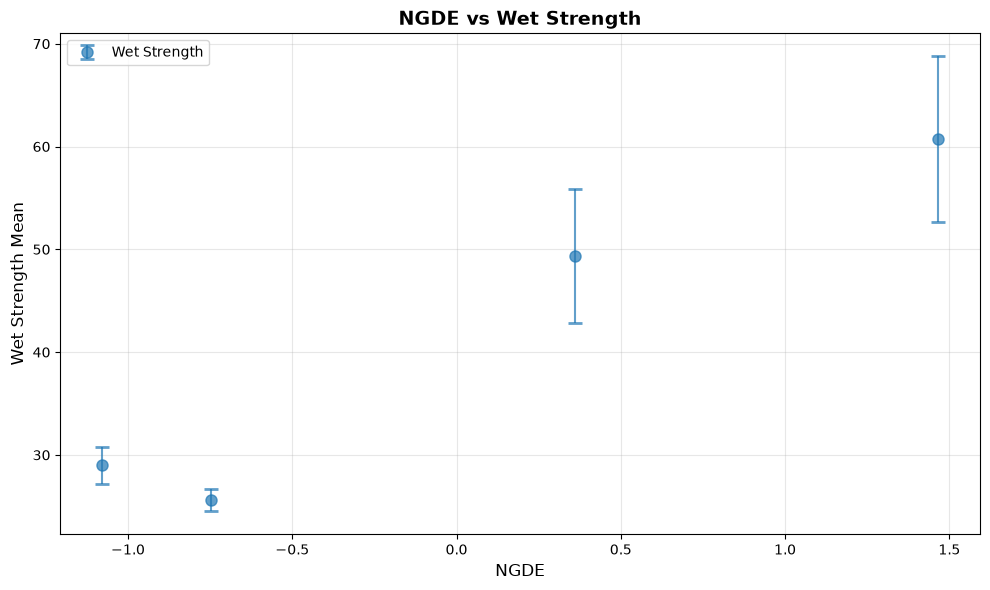


NGDE vs Wet Strength Data (4 samples):
        NGDE  Wet Strength Mean  std_Wet Strength Mean
21 -1.078765          28.978707               1.761387
22 -0.746837          25.604407               1.097392
23  0.359588          49.374470               6.506838
24  1.466014          60.731681               8.087211


In [86]:
# print out NGDE vs wet strength
import matplotlib.pyplot as plt

# Filter out rows where NGDE is NaN
df_ngde = df[df['NGDE'].notna()].copy()
ngde_var = (df_ngde['std_Wet Strength Mean']**2).to_numpy()

# Create the plot
plt.figure(figsize=(10, 6))
plt.errorbar(df_ngde['NGDE'], df_ngde['Wet Strength Mean'], 
             yerr=df_ngde['std_Wet Strength Mean'], 
             fmt='o', markersize=8, capsize=5, capthick=2, 
             label='Wet Strength', alpha=0.7)

plt.xlabel('NGDE', fontsize=12)
plt.ylabel('Wet Strength Mean', fontsize=12)
plt.title('NGDE vs Wet Strength', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nNGDE vs Wet Strength Data ({len(df_ngde)} samples):")
print(df_ngde[['NGDE', 'Wet Strength Mean', 'std_Wet Strength Mean']])

In [87]:
# implement very simple GRP for the data, mean function of 0, default kernel

import numpy as np

#get the training data from the df

rng = np.random.RandomState(1)
X = df_ngde[['NGDE']].to_numpy()
y = df_ngde['Wet Strength Mean'].to_numpy()

# create the gaussian process model 

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel
from sklearn.gaussian_process.kernels import RBF
from sklearn.gaussian_process.kernels import Matern
from sklearn.gaussian_process.kernels import WhiteKernel
from sklearn.gaussian_process.kernels import ConstantKernel

from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

from sklearn.gaussian_process.kernels import RBF

kernel = RBF(length_scale=1, length_scale_bounds=(1e-10, 1e1))

gaussian_process = GaussianProcessRegressor(
    kernel=kernel, 
    normalize_y=True, 
    n_restarts_optimizer=10,
    alpha=0
)
gaussian_process.fit(X, y)  # fit the model on the full dataset
gaussian_process.kernel_

RBF(length_scale=0.814)

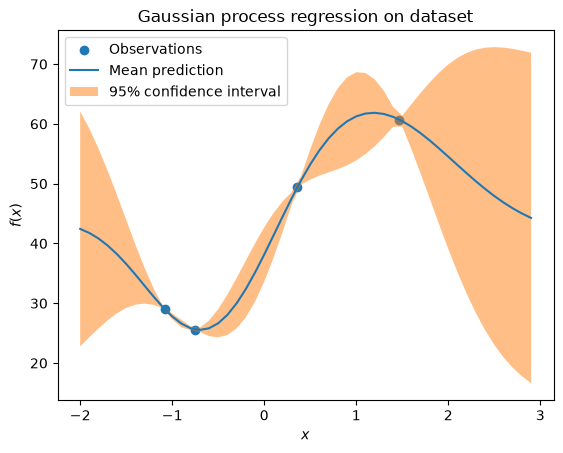

In [88]:
x_predictions = np.arange(-2, 3, .1).reshape(-1, 1)

mean_prediction, std_prediction = gaussian_process.predict(x_predictions, return_std=True) # get predictions and
# std for the full data, not just 6 points, gives you the mean at those points only not the full data

plt.scatter(X, y, label="Observations")
plt.plot(x_predictions, mean_prediction, label="Mean prediction")
plt.fill_between(
    x_predictions.ravel(),
    mean_prediction - 1.96 * std_prediction,
    mean_prediction + 1.96 * std_prediction,
    alpha=0.5,  # shading setting
    label=r"95% confidence interval",
)
plt.legend()
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
_ = plt.title("Gaussian process regression on dataset")

In [89]:
# get predictions for the training data to check

print(X)
print(y)

mean_prediction, std_prediction = gaussian_process.predict(X, return_std=True)

print(mean_prediction)
print(std_prediction)

[[-1.07876491]
 [-0.74683725]
 [ 0.3595883 ]
 [ 1.46601386]]
[28.97870736 25.60440652 49.37446985 60.73168101]
[28.97870736 25.60440652 49.37446985 60.73168101]
[0.00000000e+00 0.00000000e+00 0.00000000e+00 1.52772151e-07]


In [90]:
# now we will figure out the evaluation procedure

In [91]:
# train error

# This tells you for the data the model was trained on, how well can the model fit that
# for us, if we do LOOCV, we would average the train error over all the folds

In [92]:
# validation error

# This is for the data that the model was not trained on, how well is the model doing
# for us, if we do LOOCV, we would average the validation error over all the folds

In [93]:
# break X and y into LOOCV folds, refit the model on each fold/ print
# evaluation metrics

import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score


kernel = RBF(length_scale=1.0, length_scale_bounds=(1e-10, 1e4))

model = GaussianProcessRegressor(
    kernel=kernel, 
    normalize_y=True, 
    n_restarts_optimizer=10,
    alpha=0
)

# LOOCV cross-validation
from sklearn.model_selection import LeaveOneOut

loo = LeaveOneOut()

train_r2_scores = []
val_r2_scores = []

fold_num = 1
for train_idx, val_idx in loo.split(X):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]
    
    # Fit model on training fold
    model.fit(X_train, y_train)
    
    # Evaluate on validation fold (single point)
    val_pred = model.predict(X_val)
    val_r2 = r2_score(y_val, val_pred)
    val_r2_scores.append(val_r2)

    # Evaluate on training fold
    train_pred = model.predict(X_train)
    train_r2 = r2_score(y_train, train_pred)
    train_r2_scores.append(train_r2)
    
    print(f"Fold {fold_num}: Val Prediction = {val_pred[0]:.3f}, Actual = {y_val[0]:.3f}")
    fold_num += 1

# Calculate averages
avg_train_r2 = np.mean(train_r2_scores)
avg_val_r2 = np.mean(val_r2_scores)

# Create summary table
results_df = pd.DataFrame({
    'Error Source': ['Goal Performance', 'Train Error', 'Validation Error', 'Test Error'],
    'Value': [
        'R² = .8',
        f'R² = {avg_train_r2:.3f}',
        f'R² = {avg_val_r2:.3f}',
        ''
    ]
})

print("\n" + "="*50)
print("EVALUATION SUMMARY")
print("="*50)
print(results_df.to_string(index=False))

Fold 1: Val Prediction = 24.259, Actual = 28.979
Fold 2: Val Prediction = 32.079, Actual = 25.604
Fold 3: Val Prediction = 39.200, Actual = 49.374
Fold 4: Val Prediction = 35.543, Actual = 60.732

EVALUATION SUMMARY
    Error Source      Value
Goal Performance    R² = .8
     Train Error R² = 1.000
Validation Error   R² = nan
      Test Error           


c:\Users\Brooke Brocker\foam-project\.venv\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\Brooke Brocker\foam-project\.venv\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\Brooke Brocker\foam-project\.venv\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
c:\Users\Brooke Brocker\foam-project\.venv\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)
